In [12]:
import joblib
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import shap


In [13]:
pip install shap

Note: you may need to restart the kernel to use updated packages.


In [14]:
# Load the scaled classification data
data = joblib.load("preprocessed_classification.pkl")

X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"]
y_test = data["y_test"]

# Load the best classification model 
model = joblib.load("models/best_classification_model.pkl")

with open("decoding_dicts.json", "r") as file:
    decoding = json.load(file)

activity_decoding = {int(key): value for key, value in decoding["activity_decoding"].items()}

print("Model:", type(model).__name__)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Model classes:", model.classes_)

Model: RandomForestClassifier
X_train: (171, 15)
X_test: (43, 15)
Model classes: [0 1 2]


c:\Users\ThinkPad\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.9.0 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ThinkPad\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.9.0 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [15]:
explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values( X_test)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (43, 15, 3)


In [16]:
sample_index = 0  
sample=X_test.iloc[sample_index:sample_index+1]
true_class = y_test.iloc[sample_index]
predicted_class = model.predict(sample)[0]
predicted_probabilities = (model.predict_proba(sample)[0])

print("True class:", true_class)
print("Predicted class:", predicted_class)
print("Predicted probabilities:", predicted_probabilities)

# Find the position of the predicted class
predicted_class_index = np.where(model.classes_ == predicted_class)[0][0]
predicted_probability = float(predicted_probabilities[predicted_class_index])


true_class_name = activity_decoding[true_class]
predicted_class_name = activity_decoding[predicted_class]

print("True class:", true_class_name)
print("Predicted class:", predicted_class_name)
print(f"Predicted probability: " f"{predicted_probability:.4f}")


print("\nProbabilities for all classes:")

for class_label, probability in zip(model.classes_, predicted_probabilities):
    print(
        f"{activity_decoding[int(class_label)]}: "
        f"{probability:.4f}"
    )

True class: 2
Predicted class: 1
Predicted probabilities: [0.10704286 0.50067937 0.39227778]
True class: High Activity
Predicted class: Normal Activity
Predicted probability: 0.5007

Probabilities for all classes:
Low Activity: 0.1070
Normal Activity: 0.5007
High Activity: 0.3923


In [18]:
# Extract SHAP values for the predicted class only
class_shap_values = (shap_values[ sample_index,:,predicted_class_index])

# Extract the base probability for the predicted class

base_value = float(
    np.asarray(
        explainer.expected_value
    ).reshape(-1)[
        predicted_class_index
    ]
)


print("Explained class:", predicted_class_name)

print(f"Base probability: " f"{base_value:.4f}")

Explained class: Normal Activity
Base probability: 0.3343


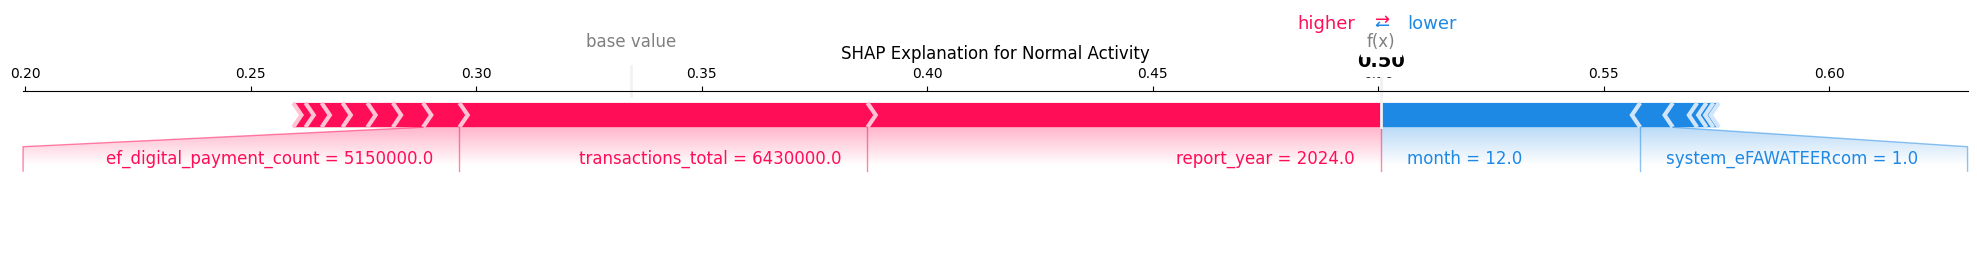

In [20]:
shap.force_plot(
    base_value,
    class_shap_values,
    sample.iloc[0],
    feature_names=X_test.columns.tolist(),
    matplotlib=True,
    show=False
)


plt.title(
    f"SHAP Explanation for "
    f"{predicted_class_name}"
)

plt.tight_layout()

plt.show()

In [21]:
shap_table = pd.DataFrame({"Feature": X_test.columns, "Input Value": (sample.iloc[0].values), "SHAP Value": (class_shap_values)})


shap_table["Impact"] = np.where(shap_table["SHAP Value"] > 0, 
        f"Increased probability of " 
        f"{predicted_class_name}", 

        np.where(shap_table["SHAP Value"] < 0,
        f"Reduced probability of " 
        f"{predicted_class_name}",

        "No impact"
    )
)


shap_table["Absolute Impact"] = (shap_table["SHAP Value"].abs())


shap_table = shap_table.sort_values(by="Absolute Impact", ascending=False).reset_index(drop=True)


display(
    shap_table[
        [
            "Feature",
            "Input Value",
            "SHAP Value",
            "Impact"
        ]
    ]
)

,Feature,Input Value,SHAP Value,Impact
0,report_year,2024,0.113928,Increased probability of Normal Activity
1,transactions_total,6430000,0.090487,Increased probability of Normal Activity
2,month,12,-0.057431,Reduced probability of Normal Activity
3,ef_digital_payment_count,5150000,0.008074,Increased probability of Normal Activity
4,system_eFAWATEERcom,1,-0.007243,Reduced probability of Normal Activity
5,ach_jod_transaction_count,0,0.006694,Increased probability of Normal Activity
6,wallet_commercial_count,0,0.005650,Increased probability of Normal Activity
7,returned_cheque_count,0,0.005507,Increased probability of Normal Activity
8,system_CliQ,0,-0.005389,Reduced probability of Normal Activity
9,system_ECCU,0,0.004639,Increased probability of Normal Activity


In [22]:
print("Features that increased the probability:")

display(
    shap_table[
        shap_table["SHAP Value"] > 0
    ][
        [
            "Feature",
            "Input Value",
            "SHAP Value"
        ]
    ].head(5)
)


print("Features that reduced the probability:")

display(
    shap_table[
        shap_table["SHAP Value"] < 0
    ][
        [
            "Feature",
            "Input Value",
            "SHAP Value"
        ]
    ].head(5)
)

Features that increased the probability:


,Feature,Input Value,SHAP Value
0,report_year,2024,0.113928
1,transactions_total,6430000,0.090487
3,ef_digital_payment_count,5150000,0.008074
5,ach_jod_transaction_count,0,0.006694
6,wallet_commercial_count,0,0.005650


Features that reduced the probability:


,Feature,Input Value,SHAP Value
2,month,12,-0.057431
4,system_eFAWATEERcom,1,-0.007243
8,system_CliQ,0,-0.005389
12,system_JoMoPay,0,-0.002061
13,users_total,4540000,-0.001533


In [23]:
total_shap_effect = float(
    class_shap_values.sum()
)


reconstructed_prediction = (
    base_value + total_shap_effect
)


print(
    f"Base value: "
    f"{base_value:,.2f} JOD"
)

print(
    f"Total SHAP effect: "
    f"{total_shap_effect:,.2f} JOD"
)

print(
    f"SHAP reconstructed prediction: "
    f"{reconstructed_prediction:,.2f} JOD"
)

print(
    f"Original model prediction: "
    f"{predicted_probability:,.2f} JOD"
)

Base value: 0.33 JOD
Total SHAP effect: 0.17 JOD
SHAP reconstructed prediction: 0.50 JOD
Original model prediction: 0.50 JOD


In [24]:
#Using joblib save the shap explainer

joblib.dump(
    explainer,
    "models/classification_shap_explainer.pkl"
)


print(
    "SHAP explainer saved to: "
    "models/classification_shap_explainer.pkl"
)

SHAP explainer saved to: models/classification_shap_explainer.pkl
